#TC2034 Modelación del Aprendizaje con Inteligencia Artificial
##Aprendizaje No Supervisado
###Notebook para Hierarchical Clustering
Steffany Mishell Lara Muy
A00838589





In [14]:
import plotly.figure_factory as ff
import numpy as np
np.random.seed(1)

X = np.random.rand(15, 12) # 15 samples, with 12 dimensions each
fig = ff.create_dendrogram(X)
fig.update_layout(width=800, height=500)
fig.show()


#otro ejemplo

X = np.random.rand(10, 12)
names = ['Jack', 'Oxana', 'John', 'Chelsea', 'Mark', 'Alice', 'Charlie', 'Rob', 'Lisa', 'Lily']
fig = ff.create_dendrogram(X, orientation='left', labels=names)
fig.update_layout(width=800, height=800)
fig.show()


In [15]:
import plotly.graph_objects as go
import plotly.figure_factory as ff

import numpy as np
from scipy.spatial.distance import pdist, squareform


# get data
data = np.genfromtxt("http://files.figshare.com/2133304/ExpRawData_E_TABM_84_A_AFFY_44.tab",
                     names=True,usecols=tuple(range(1,30)),dtype=float, delimiter="\t")
data_array = data.view((float, len(data.dtype.names)))

print(data_array)
data_array = data_array.transpose()
labels = data.dtype.names

# Initialize figure by creating upper dendrogram
fig = ff.create_dendrogram(data_array, orientation='bottom', labels=labels)
for i in range(len(fig['data'])):
    fig['data'][i]['yaxis'] = 'y2'

# Create Side Dendrogram
dendro_side = ff.create_dendrogram(data_array, orientation='right')
for i in range(len(dendro_side['data'])):
    dendro_side['data'][i]['xaxis'] = 'x2'

# Add Side Dendrogram Data to Figure
for data in dendro_side['data']:
    fig.add_trace(data)

# Create Heatmap
dendro_leaves = dendro_side['layout']['yaxis']['ticktext']
dendro_leaves = list(map(int, dendro_leaves))
data_dist = pdist(data_array)
heat_data = squareform(data_dist)
heat_data = heat_data[dendro_leaves,:]
heat_data = heat_data[:,dendro_leaves]

heatmap = [
    go.Heatmap(
        x = dendro_leaves,
        y = dendro_leaves,
        z = heat_data,
        colorscale = 'Blues'
    )
]

heatmap[0]['x'] = fig['layout']['xaxis']['tickvals']
heatmap[0]['y'] = dendro_side['layout']['yaxis']['tickvals']

# Add Heatmap Data to Figure
for data in heatmap:
    fig.add_trace(data)

# Edit Layout
fig.update_layout({'width':800, 'height':800,
                         'showlegend':False, 'hovermode': 'closest',
                         })
# Edit xaxis
fig.update_layout(xaxis={'domain': [.15, 1],
                                  'mirror': False,
                                  'showgrid': False,
                                  'showline': False,
                                  'zeroline': False,
                                  'ticks':""})
# Edit xaxis2
fig.update_layout(xaxis2={'domain': [0, .15],
                                   'mirror': False,
                                   'showgrid': False,
                                   'showline': False,
                                   'zeroline': False,
                                   'showticklabels': False,
                                   'ticks':""})

# Edit yaxis
fig.update_layout(yaxis={'domain': [0, .85],
                                  'mirror': False,
                                  'showgrid': False,
                                  'showline': False,
                                  'zeroline': False,
                                  'showticklabels': False,
                                  'ticks': ""
                        })
# Edit yaxis2
fig.update_layout(yaxis2={'domain':[.825, .975],
                                   'mirror': False,
                                   'showgrid': False,
                                   'showline': False,
                                   'zeroline': False,
                                   'showticklabels': False,
                                   'ticks':""})

# Plot!
fig.show()

[[ 6.3739767  6.4981704  6.271771  ...  6.112102   6.359853   6.010906 ]
 [ 5.986182   4.861167   5.5666986 ...  5.0324726  6.12955    5.4538217]
 [ 7.468118   6.9479957  6.9435835 ...  6.93343    8.460821   6.8208113]
 ...
 [11.745089  11.33983   11.840397  ... 11.411251  10.814936  11.467866 ]
 [13.277803  13.031992  13.332481  ... 13.084589  12.888793  13.08952  ]
 [13.067169  12.7244425 13.051369  ... 12.768577  12.673793  12.792053 ]]


In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster import hierarchy

df = pd.read_csv('penguins.csv')
print(df.head(5))

#print(df.shape) # (344, 9)
df = df[['bill_length_mm', 'flipper_length_mm']]
df = df.dropna(axis=0)

   rowid species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0      1  Adelie  Torgersen            39.1           18.7              181.0   
1      2  Adelie  Torgersen            39.5           17.4              186.0   
2      3  Adelie  Torgersen            40.3           18.0              195.0   
3      4  Adelie  Torgersen             NaN            NaN                NaN   
4      5  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  year  
0       3750.0    male  2007  
1       3800.0  female  2007  
2       3250.0  female  2007  
3          NaN     NaN  2007  
4       3450.0  female  2007  


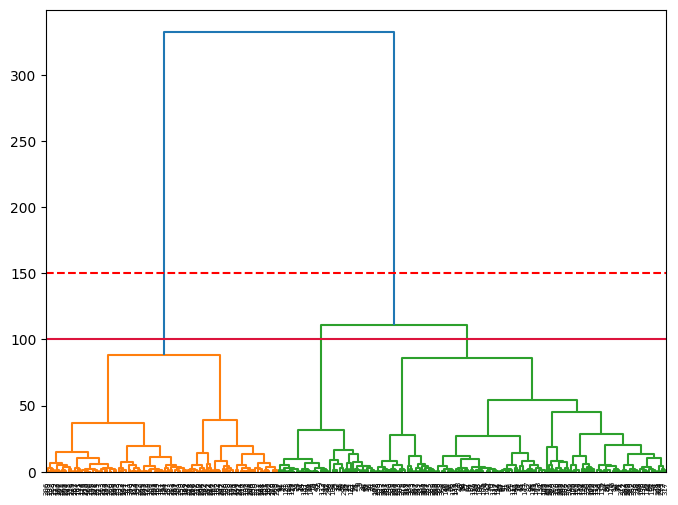

In [17]:
clusters = hierarchy.linkage(df, method="ward")

plt.figure(figsize=(8, 6))
dendrogram = hierarchy.dendrogram(clusters)
# Plotting a horizontal line based on the first biggest distance between clusters
plt.axhline(150, color='red', linestyle='--');
# Plotting a horizontal line based on the second biggest distance between clusters
plt.axhline(100, color='crimson');

In [18]:
clustering_model = AgglomerativeClustering(n_clusters=3, linkage="ward")
clustering_model.fit(df)
labels = clustering_model.labels_

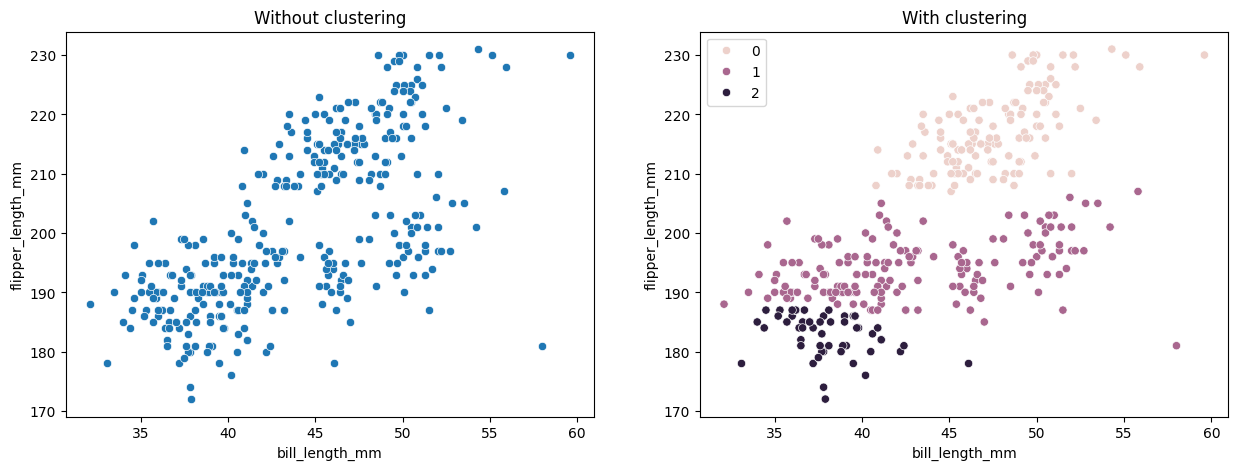

In [19]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15,5))
sns.scatterplot(ax=axes[0], data=df, x='bill_length_mm', y='flipper_length_mm').set_title('Without clustering')
sns.scatterplot(ax=axes[1], data=df, x='bill_length_mm', y='flipper_length_mm', hue=labels).set_title('With clustering');

In [ ]:
!pip install kneed

In [24]:

import matplotlib.pyplot as plt
from kneed import KneeLocator
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

clustering_model_no_clusters = AgglomerativeClustering(linkage="ward")
clustering_model_no_clusters.fit(df)
labels_no_clusters = clustering_model_no_clusters.labels_



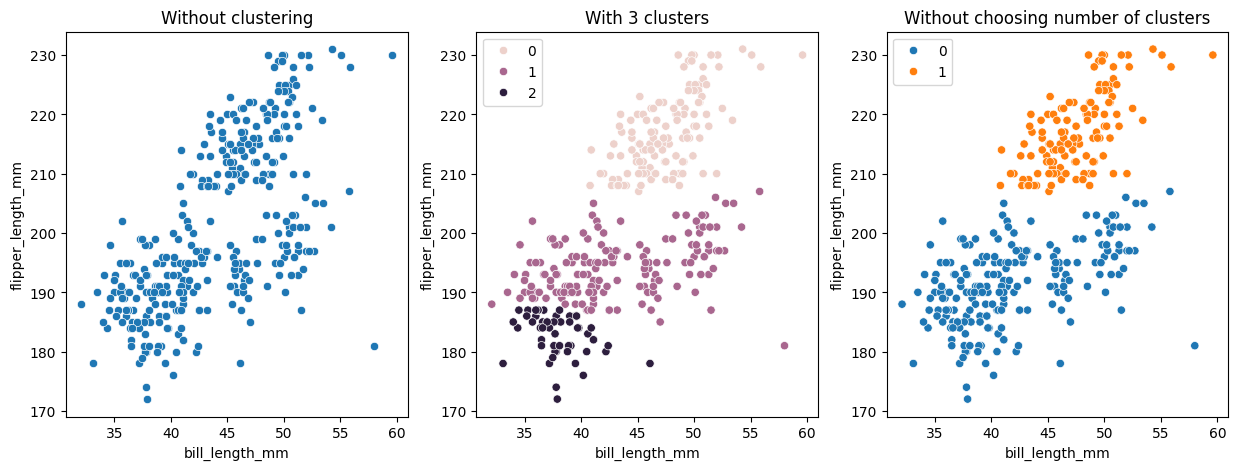

In [22]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15,5))
sns.scatterplot(ax=axes[0], data=df, x='bill_length_mm', y='flipper_length_mm').set_title('Without clustering')
sns.scatterplot(ax=axes[1], data=df, x='bill_length_mm', y='flipper_length_mm', hue=clustering_model.labels_).set_title('With 3 clusters')
sns.scatterplot(ax=axes[2], data=df, x='bill_length_mm', y='flipper_length_mm', hue=clustering_model_no_clusters.labels_).set_title('Without choosing number of clusters');

## Combinando Ambos Códigos

In [27]:
!pip install ace_tools

In [36]:
# He decidido hacer una representación gráfica del agglomerative clustering con los datos al azar del primer tutorial


import plotly.figure_factory as ff
import numpy as np
np.random.seed(1)

#otro ejemplo

X = np.random.rand(100, 12)
fig = ff.create_dendrogram(X, orientation='left')
fig.update_layout(width=800, height=800)
fig.show()

dfnuevis = pd.DataFrame(X,  columns=[f"Feature_{i+1}" for i in range(X.shape[1])])
dfnuevis.head(5)


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Feature_9,Feature_10,Feature_11,Feature_12
0,0.417022,0.720324,0.000114,0.302333,0.146756,0.092339,0.186260,0.345561,0.396767,0.538817,0.419195,0.685220
1,0.204452,0.878117,0.027388,0.670468,0.417305,0.558690,0.140387,0.198101,0.800745,0.968262,0.313424,0.692323
2,0.876389,0.894607,0.085044,0.039055,0.169830,0.878143,0.098347,0.421108,0.957890,0.533165,0.691877,0.315516
3,0.686501,0.834626,0.018288,0.750144,0.988861,0.748166,0.280444,0.789279,0.103226,0.447894,0.908596,0.293614
4,0.287775,0.130029,0.019367,0.678836,0.211628,0.265547,0.491573,0.053363,0.574118,0.146729,0.589306,0.699758


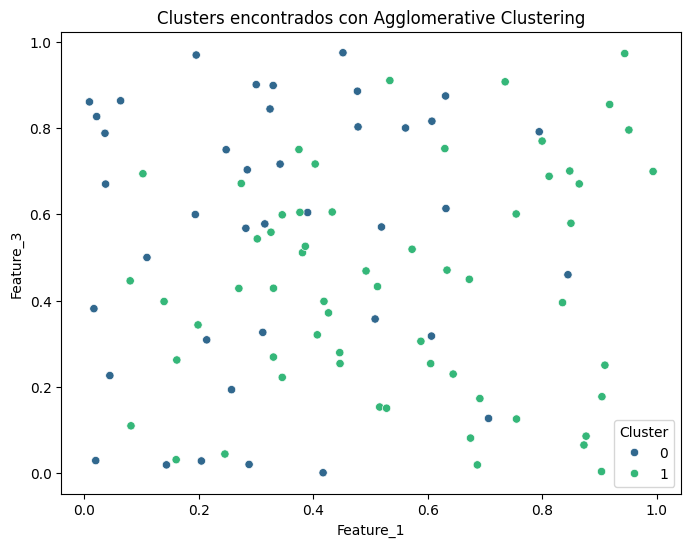

In [44]:

# Aplicar Agglomerative Clustering
modelo_cluster1 = AgglomerativeClustering(linkage="ward")
modelo_cluster1.fit(dfnuevis)

# Agregar los clusters al DataFrame
dfnuevis["Cluster"] = modelo_cluster1.labels_

# Crear gráfico con Seaborn
plt.figure(figsize=(8,6))
sns.scatterplot(data=dfnuevis, x='Feature_1', y='Feature_3', hue="Cluster", palette="viridis")
plt.title('Clusters encontrados con Agglomerative Clustering')
plt.show()

Reflexión: se han mostrado formas de hacer clustering jerarquico, con datos aleatorios, brindando una cantidad de samples y de características/cualidades que poseen. Se crea un dendograma con los datos presentes. Se me hizo muy interesante el método ward para la creación de dendograma, solo conocía el average, simple y complete linkage, por tanto, saber que existe otro método considerado "más idóneo" que estos me será muy útil en la carrera como IDM.

Lo que más llamó mi atención fue la utilización de datos reales con un dataset, además, no se debía descargar directamente si no que existen librerías que ya te permiten colocar el enlace y con funciones de Numpy logran obtener un .csv. Después me gustó mucho la relación entre el heatmap y los dendogramas. Como se sabe, cada celda de la matriz en un heatmap representa un valor numérico, mientras los dendogramas indican como los datos se agrupan según similitud. Por tanto la interpretación del gráfico impolica que si hay bloques oscuros, los valores en la región son altos al mismo tiempo que las más claras tienen menos similitud. El dendograma mostraría grupos similares así permitiendo ver patrones en agrupamiento de datos. Por ejemplo, en el dendograma para los genes r07, r06, r11, r08, r14, r15 se puede ver como el dendograma verde (lateral izquierdo) su rama principal izquierda tiene menor correlación entre ellas que la rama derecha.


Por otra parte, llamó mi atención la selección de cantidad de clusters. Al crear el modelo aglomerativo utilicé 3 clusters por elección, pero al crear otro modelo sin seleccionar previamente la cantidad de clusters creada la función creó 2 porque lo consideró más idóneo para mi dataset.


Finalmente con datos aleatorios intenté entrenar un modelo sin seleccionar la cantidad de clusters, pero como eran aleatorios el scatter plot, donde utilicé para las coordenadas X y Y dos características arbitrarias, no muestra una clara tendencia, pese a eso, el modelo elije 2 clusters para el dataset. Esta elección de un dataset aleatorio demuestra que no todos los conjuntos de datos son aptos para un entrenamiento de clusters y que pese a que la máquina haga una "predicción" de su categoría, parte de la importancia en crear un modelo reside en saber si sigue una tendencia clara y escoger el método acorde a la distribución de los datos.
